# Evaluating a classifier

A regression model can be wrong by a little or by a lot. A classifier is wrong in kinds: it can call a positive case negative, or a negative case positive, and the two mistakes rarely cost the same. A missed tumour and an unnecessary biopsy are both errors, but not equal ones. The share of correct answers can't tell them apart; the measures here can.

## A classifier to evaluate

The breast cancer dataset that comes with scikit-learn: 569 tumours, each described by 30 measurements of the cell nuclei in an image of a biopsy, and diagnosed as malignant or benign. The class the model is looking for, malignant, is called the **positive** class; that is a convention about what is being detected, not a judgement. In this dataset the target is coded 0 for malignant, so it is recoded to make malignant 1:

In [ ]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(as_frame=True)
X = cancer.data
y = (cancer.target == 0).astype(int).rename("malignant")
y.value_counts()

malignant
0    357
1    212
Name: count, dtype: int64

A stratified split, so that both sets keep the share of malignant tumours ([Overfitting and the train/test split](../ml-fundamentals/overfitting_and_the_split.ipynb)), and a [logistic regression](../algorithms/linear-models/logistic_regression.ipynb) in a pipeline with a scaler:

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
model = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
y_predicted = model.predict(X_test)

## Accuracy

**Accuracy** is the share of predictions that are correct:

$$\text{accuracy} = \frac{\text{correct predictions}}{\text{all predictions}}$$

> **A note on terms for Spanish speakers.** *Accuracy* translates as **exactitud**. *Precision*, a different measure explained below, translates as **precisión**. Translating *accuracy* as *precisión* is a common mistake that makes the two impossible to tell apart.

In [ ]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_predicted)

0.9707602339181286

A number alone means little without something to compare it with. The simplest possible classifier answers the most frequent class every time, without looking at the tumour:

In [ ]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
accuracy_score(y_test, baseline.predict(X_test))

0.6257309941520468

The model is right about 97% of the time. A classifier that never looks at a tumour and calls every one benign is right about 63% of the time, because 63% of the tumours are benign. So the model's real achievement is the distance from 63% to 97%, not 97% itself. When one class is much rarer than here, the do-nothing classifier gets very close to 100%, and accuracy stops saying anything useful: [When one class is rare](imbalanced_classes.ipynb) is about that case.

## The confusion matrix

The **confusion matrix** counts each combination of true and predicted class. Rows are the true classes, columns the predicted ones:

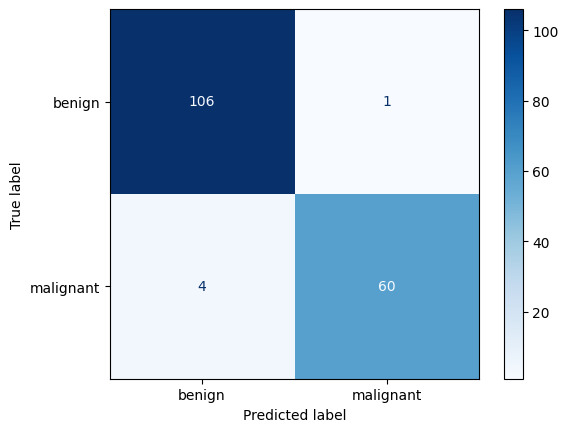

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_predicted, display_labels=["benign", "malignant"], cmap="Blues")
plt.show()

| | Predicted benign | Predicted malignant |
| --- | --- | --- |
| **Truly benign** | true negatives (TN) | false positives (FP): a false alarm, an unnecessary biopsy |
| **Truly malignant** | false negatives (FN): a missed tumour | true positives (TP) |

Of the 171 test tumours, 106 benign ones were called benign and 60 malignant ones were caught. The five errors are four missed tumours and one false alarm: most of the model's mistakes are of the costly kind.

## Precision and recall

Two measures split the errors by kind:

| Measure | Formula | The question it answers | Here |
| --- | --- | --- | --- |
| **Precision** | TP / (TP + FP) | Of the cases flagged as positive, how many are? | Of the tumours called malignant, how many are |
| **Recall** (sensitivity, true positive rate) | TP / (TP + FN) | Of the positive cases, how many were found? | Of the malignant tumours, how many were caught |

**F1** combines them in one number, their *harmonic* mean:

$$F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$$

The harmonic mean stays close to the smaller of the two: a precision of 1.0 with a recall of 0.1 gives an F1 of 0.18, where the ordinary mean would say 0.55. A classifier can't score well on F1 by being excellent at one and useless at the other.

In [ ]:
from sklearn.metrics import f1_score, precision_score, recall_score

{
    "precision": precision_score(y_test, y_predicted),
    "recall": recall_score(y_test, y_predicted),
    "F1": f1_score(y_test, y_predicted),
}

{'precision': 0.9836065573770492, 'recall': 0.9375, 'F1': 0.96}

`classification_report` gives the three measures for *each* class, treating each in turn as the positive one:

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_predicted, target_names=["benign", "malignant"]))

              precision    recall  f1-score   support

      benign       0.96      0.99      0.98       107
   malignant       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171



*Support* is the number of test cases of each class. The two averages at the bottom summarise the classes: the **macro** average weighs each class the same, and the **weighted** average weighs them by their support, so the larger class dominates it. With more than two classes, these averages are how precision, recall and F1 are reported.

## The threshold

`predict` hides a decision. The model computes a probability of malignancy, and `predict` answers "malignant" when it is above 0.5. Nothing makes 0.5 right: moving the **threshold** exchanges one kind of error for the other. The same model, read at several thresholds:

In [ ]:
import pandas as pd
from sklearn.metrics import confusion_matrix

probability_malignant = model.predict_proba(X_test)[:, 1]


def at_threshold(threshold):
    flagged = (probability_malignant >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, flagged).ravel()
    return {"precision": tp / (tp + fp), "recall": tp / (tp + fn), "missed tumours (FN)": fn, "false alarms (FP)": fp}


pd.DataFrame({threshold: at_threshold(threshold) for threshold in (0.05, 0.2, 0.5, 0.8, 0.95)}).T.rename_axis("threshold").round(3)

,precision,recall,missed tumours (FN),false alarms (FP)
threshold,,,,
0.05,0.821,1.000,0.0,14.0
0.20,0.955,0.984,1.0,3.0
0.50,0.984,0.938,4.0,1.0
0.80,1.000,0.875,8.0,0.0
0.95,1.000,0.750,16.0,0.0


At the default 0.5, four tumours are missed and one alarm is false. Lowering the threshold to 0.2 catches all but one malignant tumour, at the cost of two more false alarms; at 0.05 every malignant tumour is caught, and 14 benign ones are sent to a biopsy they didn't need. Raising it does the opposite, until at 0.95 there are no false alarms and 16 missed tumours. Recall goes up as precision goes down, and which point to choose is not a statistical question: it depends on what each kind of error costs. For screening, a missed tumour costs far more than a biopsy, so the threshold goes low.

## ROC curve and AUC

The **ROC curve** draws every threshold at once: for each one, the recall (the true positive rate) against the **false positive rate**, FP / (FP + TN), the share of benign tumours flagged by mistake. A model that guesses at random lies on the diagonal; a perfect one goes straight up to a recall of 1 with no false positives. The **area under the curve** (AUC) summarises it: 0.5 for guessing, 1 for perfect. It has a direct meaning: the probability that the model gives a randomly chosen malignant tumour a higher score than a randomly chosen benign one.

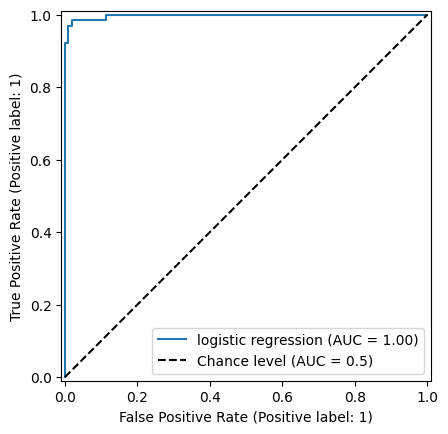

In [ ]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, probability_malignant, name="logistic regression", plot_chance_level=True)
plt.show()

The curve climbs almost straight to the top-left corner, and the AUC is about 0.998 (1.00 in the legend): for almost any malignant tumour and any benign one, the model gives the malignant one the higher probability. This is a dataset where the measurements separate the classes very well. The ROC curve has a weak spot, though: its false positive rate is relative to the number of negatives, so when negatives vastly outnumber positives, a large number of false alarms is a small rate, and the curve looks better than the model is. The precision–recall curve of [When one class is rare](imbalanced_classes.ipynb) doesn't have that problem.

## Choosing a measure

| Situation | Measure to watch | Why |
| --- | --- | --- |
| Classes of similar size, errors of similar cost | accuracy, F1 | one number is enough |
| A missed positive is costly: screening, fraud | recall, at an acceptable precision | the threshold is lowered until few positives are missed |
| A false alarm is costly: a spam filter, an automatic block | precision, at an acceptable recall | the threshold is raised until few alarms are false |
| Comparing models before choosing a threshold | AUC | it covers every threshold |
| One class is rare | precision, recall and their curve; never accuracy alone | [When one class is rare](imbalanced_classes.ipynb) |

In every case the measure is computed on data the model didn't learn from, and the threshold, like any other setting, is chosen on a validation set and not on the test set ([Validation and model selection](../ml-fundamentals/validation_and_model_selection.ipynb)).